# 02 · Forecasting arena (v2 world)

> **Independent educational simulation. Not an airline system or an approved maintenance, airworthiness or dispatch tool.** Falcon Hub Airways is fictional and every airline number below is SIMULATED by this repo's code: a simulated planning snapshot, not operator data. Provenance tags: **REAL** (public data), **DERIVED** (computed by code), **ASSUMED** (a config planning assumption), **SIMULATED** (simulator output).

**The planner's question.** Spare-parts demand is mostly intermittent: a rotable is removed once every few weeks, nearly always one unit at a time. Stocking decisions need a demand rate *and* a sense of its tail. This notebook asks, honestly:

1. which forecasting method wins on the selection window, and does that ranking survive on the holdout?
2. were the frozen per-cell champions still the best on unseen data? (Mostly not, and that is reported.)
3. does a reliability model (removals per flight hour or cycle, with a Gamma–Poisson posterior) beat the Croston family it competes with?
4. are the methods implemented correctly? (Checked on a REAL public benchmark.)
5. after the holdout, how close were the history-based estimates to the hidden truth, compared with the vendor quotes?

Method rules (rolling origins 78–98, champion = lowest mean MASE per cell, the all-zero forecast never eligible) were fixed before the v2 world existed and were not changed after seeing v2 errors. A v1 world was archived after a domain review; see `archive/v1`.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))            # notebooks/_style.py
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from _style import *                            # palette, ROOT, stamp(), aed_m(), load_json(), ci()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("project root:", ROOT)
import duckdb
from gnm.forecasting.classify import build_part_attributes
con = duckdb.connect(str(ROOT / "data" / "processed" / "grounded.duckdb"), read_only=True)
q = lambda sql: con.execute(sql).df()
fsum = load_json("outputs/forecasting/forecasting_summary.json")
print("selection origins:", fsum["origins"], "| methods:", ", ".join(fsum["methods"]))
print("champion table sha256:", fsum["champions_sha256"][:16], "... (frozen before the holdout)")

project root: /Users/akashgajjar/grounded-no-more
selection origins: [78, 82, 86, 90, 94, 98] | methods: adida, bootstrap, croston, imapa, ma, naive, reliability, sba, tsb, zero
champion table sha256: 0b1c78288bdb2564 ... (frozen before the holdout)


## 1. Demand classes (ADI / CV²)

Syntetos–Boylan classification on the training weeks 0–77: **ADI** is the average gap between demand weeks and **CV²** the squared coefficient of variation of the non-zero demand sizes. The cut-offs 1.32 and 0.49 split parts into smooth, erratic, intermittent and lumpy. We recompute the classes here and check them against the site export.

demand class agrees with docs/data/parts.json for 100% of 120 parts


part_class,C,E,R,All
demand_class,,,,
erratic,3,0,0,3
insufficient_data,0,0,1,1
intermittent,13,32,37,82
lumpy,2,0,0,2
smooth,27,3,2,32
All,45,35,40,120


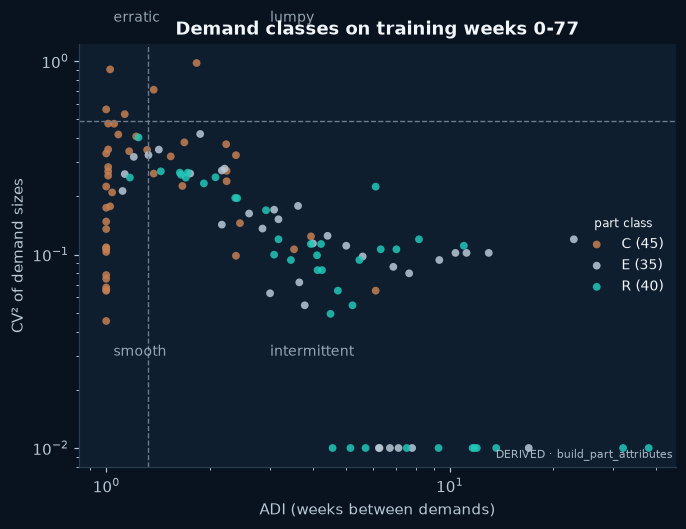

In [2]:
mr = q("select pn, week, sum(qty) as qty from material_requests group by all")
demand = mr.pivot(index="pn", columns="week", values="qty").reindex(columns=range(104)).fillna(0)
pm = q("select * from part_master").set_index("pn")
demand = demand.reindex(pm.index).fillna(0)
attrs = build_part_attributes(demand, pm.reset_index(), train_weeks=(0, 77))
site = pd.DataFrame(load_json("docs/data/parts.json")["parts"]).set_index("pn")
agree = (attrs.demand_class == site.demand_class.reindex(attrs.index)).mean()
print(f"demand class agrees with docs/data/parts.json for {agree:.0%} of {len(attrs)} parts")
display(pd.crosstab(attrs.demand_class, attrs.part_class, margins=True))
fig, ax = plt.subplots(figsize=(7, 5))
cols = {"C": COPPER, "E": TITANIUM, "R": TEAL}
d = attrs.dropna(subset=["adi", "cv2"])
for c, g in d.groupby("part_class"):
    ax.scatter(g.adi, g.cv2.clip(lower=0.01), s=26, color=cols[c], alpha=0.85, label=f"{c} ({len(g)})", edgecolor="none")
ax.axvline(1.32, color=SLATE, lw=0.9, ls="--"); ax.axhline(0.49, color=SLATE, lw=0.9, ls="--")
for x, y, t in [(1.05, 1.6, "erratic"), (1.05, 0.03, "smooth"), (3.0, 0.03, "intermittent"), (3.0, 1.6, "lumpy")]:
    ax.text(x, y, t, color=TITANIUM, fontsize=9, alpha=0.8)
ax.set(xscale="log", yscale="log", xlabel="ADI (weeks between demands)", ylabel="CV² of demand sizes",
       title="Demand classes on training weeks 0-77")
ax.legend(frameon=False, title="part class", title_fontsize=8); stamp(ax, "build_part_attributes", "DERIVED"); plt.show()

Consumables are mostly smooth (frequent line usage). Rotables and expendables are mostly intermittent. That is where classical forecasting struggles, and where the Croston family (Croston, SBA, TSB), temporal aggregation (ADIDA, IMAPA), the bootstrap and the reliability model compete.

## 2. Leaderboard: selection vs holdout

MASE (mean absolute scaled error; below 1 beats the in-sample naive benchmark) per method and part class, with 95% bootstrap CIs over parts. Selection = rolling origins on history weeks 78–103; holdout = the history seed's continuation, weeks 104–155, a world never seen before the freeze. The all-zero forecast is shown as a benchmark only.

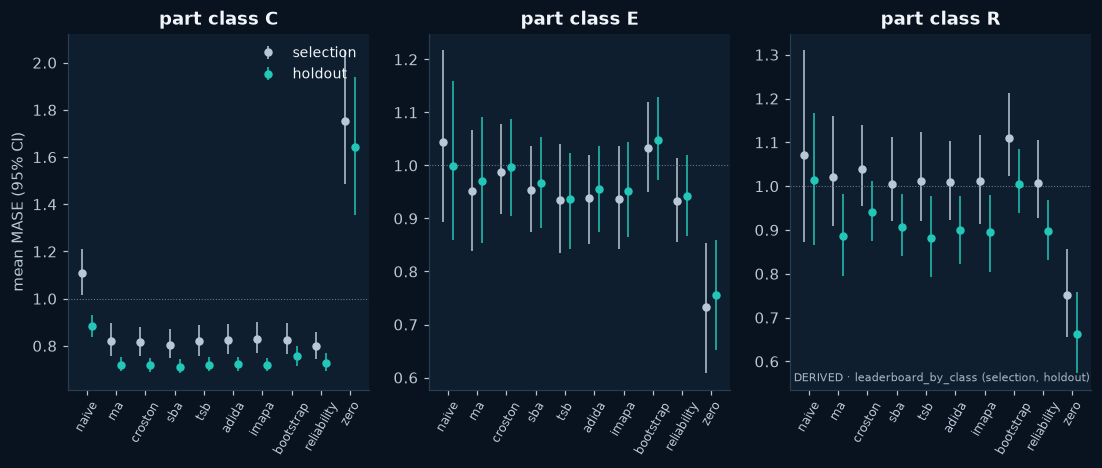

,part_class,method,mase_sel,mase_hol,rank_sel,rank_hol,pinball_q90_sel,pinball_q90_hol,cov_q90_sel,cov_q90_hol
7,C,sba,0.805,0.711,2.0,1.0,2.415,1.688,0.822,0.852
2,C,croston,0.815,0.719,3.0,2.0,2.270,1.579,0.841,0.887
4,C,ma,0.820,0.720,5.0,3.0,2.307,1.749,0.848,0.878
8,C,tsb,0.820,0.721,4.0,4.0,2.319,1.601,0.833,0.870
3,C,imapa,0.830,0.721,8.0,5.0,2.373,1.664,0.844,0.870
0,C,adida,0.827,0.721,7.0,6.0,2.375,1.668,0.844,0.869
6,C,reliability,0.801,0.728,1.0,7.0,2.030,1.518,0.867,0.906
1,C,bootstrap,0.826,0.756,6.0,8.0,1.987,1.567,0.944,0.969
5,C,naive,1.107,0.884,9.0,9.0,5.845,4.124,0.607,0.607
18,E,tsb,0.934,0.937,2.0,1.0,0.303,0.324,0.919,0.890


class C: Spearman rank correlation selection vs holdout = +0.53; best on selection reliability, best on holdout sba
class E: Spearman rank correlation selection vs holdout = +0.95; best on selection reliability, best on holdout tsb
class R: Spearman rank correlation selection vs holdout = +0.47; best on selection sba, best on holdout tsb


In [3]:
sel = pd.read_csv(ROOT / "outputs/forecasting/leaderboard_by_class.csv")
hol = pd.read_csv(ROOT / "outputs/holdout/forecast_leaderboard_by_class.csv")
methods = [m for m in ["naive", "ma", "croston", "sba", "tsb", "adida", "imapa", "bootstrap", "reliability", "zero"] if m in set(sel.method)]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, c in zip(axes, ["C", "E", "R"]):
    for df, col, lab, off in [(sel, TITANIUM, "selection", -0.17), (hol, TEAL, "holdout", 0.17)]:
        g = df[df.part_class == c].set_index("method").reindex(methods)
        x = np.arange(len(methods)) + off
        ax.errorbar(x, g.mase, yerr=[g.mase - g.mase_ci_lo, g.mase_ci_hi - g.mase], fmt="o", color=col, ms=4.5,
                    elinewidth=1, capsize=0, label=lab)
    ax.set_xticks(range(len(methods))); ax.set_xticklabels(methods, rotation=60, fontsize=8)
    ax.set_title(f"part class {c}"); ax.axhline(1, color=SLATE, lw=0.7, ls=":")
axes[0].set_ylabel("mean MASE (95% CI)"); axes[0].legend(frameon=False)
stamp(axes[-1], "leaderboard_by_class (selection, holdout)", "DERIVED"); plt.show()
cmp = sel.merge(hol, on=["part_class", "method"], suffixes=("_sel", "_hol"))
cmp = cmp[cmp.method != "zero"]
cmp["rank_sel"] = cmp.groupby("part_class").mase_sel.rank()
cmp["rank_hol"] = cmp.groupby("part_class").mase_hol.rank()
display(cmp[["part_class", "method", "mase_sel", "mase_hol", "rank_sel", "rank_hol", "pinball_q90_sel", "pinball_q90_hol",
             "cov_q90_sel", "cov_q90_hol"]].sort_values(["part_class", "rank_hol"]).round(3))
for c, g in cmp.groupby("part_class"):
    rho = g[["mase_sel", "mase_hol"]].corr(method="spearman").iloc[0, 1]
    best_s, best_h = g.loc[g.mase_sel.idxmin(), "method"], g.loc[g.mase_hol.idxmin(), "method"]
    print(f"class {c}: Spearman rank correlation selection vs holdout = {rho:+.2f}; best on selection {best_s}, best on holdout {best_h}")

Two things matter for a planner:

* **Point accuracy is close to a tie.** Within a part class the methods' CIs overlap heavily, on both windows, and the selection ranking only partly carries over to the holdout. No method dominates.
* **The tail matters more than the mean for stocking.** The q90 pinball loss and the q90 coverage show which methods give usable upper quantiles. That is what a reorder point or a float size is built on.

## 3. Champion check on the holdout

Were the frozen per-cell champions still the best on unseen data? `champion_rank` is the champion's holdout MASE rank among the 9 eligible methods in its cell (1 = best).

,demand_class,part_class,n_parts,champion,champion_mase,best_in_hindsight,best_mase,champion_rank,n_methods,gap_to_best
0,erratic,C,3,reliability,0.595,adida,0.582,6,9,0.013
1,insufficient_data,R,1,reliability,1.095,sba,1.073,3,9,0.021
2,intermittent,C,13,reliability,0.783,sba,0.776,3,9,0.007
3,intermittent,E,32,tsb,0.954,tsb,0.954,1,9,0.000
4,intermittent,R,37,sba,0.917,tsb,0.886,6,9,0.031
5,lumpy,C,2,reliability,0.788,imapa,0.772,6,9,0.016
6,smooth,C,27,sba,0.690,sba,0.690,1,9,0.000
7,smooth,E,3,reliability,0.726,sba,0.722,2,9,0.004
8,smooth,R,2,reliability,0.611,reliability,0.611,1,9,0.000


champion best on the holdout in 3 of 9 cells; median rank 3 of 9; largest MASE gap to the best 0.031
intermittent rotables (37 PNs): champion sba ranks 6 of 9 (MASE 0.917 vs tsb 0.886)


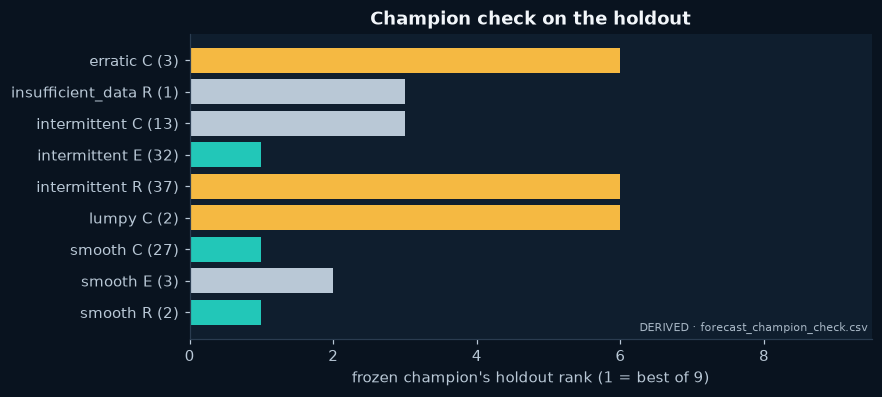

In [4]:
cc = pd.read_csv(ROOT / "outputs/holdout/forecast_champion_check.csv")
cc["gap_to_best"] = cc.champion_mase - cc.best_mase
display(cc.round(3))
n_best = int((cc.champion_rank == 1).sum())
ir = cc[(cc.demand_class == "intermittent") & (cc.part_class == "R")].iloc[0]
print(f"champion best on the holdout in {n_best} of {len(cc)} cells; median rank {cc.champion_rank.median():.0f} of {int(cc.n_methods.max())}; "
      f"largest MASE gap to the best {cc.gap_to_best.max():.3f}")
print(f"intermittent rotables ({int(ir.n_parts)} PNs): champion {ir.champion} ranks {int(ir.champion_rank)} of {int(ir.n_methods)} "
      f"(MASE {ir.champion_mase:.3f} vs {ir.best_in_hindsight} {ir.best_mase:.3f})")
fig, ax = plt.subplots(figsize=(8, 3.6))
lab = cc.demand_class + " " + cc.part_class + " (" + cc.n_parts.astype(str) + ")"
ax.barh(lab, cc.champion_rank, color=[TEAL if r == 1 else (AMBER if r >= 5 else TITANIUM) for r in cc.champion_rank])
ax.invert_yaxis(); ax.set(xlabel="frozen champion's holdout rank (1 = best of 9)", xlim=(0, 9.5), title="Champion check on the holdout")
stamp(ax, "forecast_champion_check.csv", "DERIVED"); plt.show()

**The honest reading:** the frozen champions were the best on the holdout in only a minority of cells, and for intermittent rotables SBA, the selection champion, ranks in the middle of the field. The MASE gaps to the best method are small, though, because the methods are close (section 2). Nothing was re-selected after the holdout. The consequence for planning is modest: the rotable policies use the reliability rate (section 4) rather than the per-cell champion, and stock levels depend far more on the pipeline and the protection level than on the second decimal of a MASE.

## 4. The reliability model vs the Croston family

For rotables and expendables the planner does not have to treat demand as an anonymous time series: removals are driven by exposure. The reliability model estimates removals per flight hour or cycle with a Gamma–Poisson posterior and multiplies by planned exposure. Is it better than the best Croston-family method in each class (selection window)?

,part_class,reliability_mase,reliability_ci,best_croston_family,croston_family_mase,croston_family_ci,mase_verdict,reliability_better,cis_overlap,reliability_pinball_q90,croston_family_pinball_q90
0,C,0.801039,"[0.7443, 0.8607]",sba,0.804654,"[0.7468, 0.8712]",reliability better,True,True,2.030370,2.415185
1,E,0.933540,"[0.8553, 1.0142]",tsb,0.934213,"[0.834, 1.0411]",tie (|diff| < 0.001),False,True,0.257143,0.302857
2,R,1.006314,"[0.927, 1.1062]",sba,1.005687,"[0.9196, 1.1115]",tie (|diff| < 0.001),False,True,0.229583,0.243333


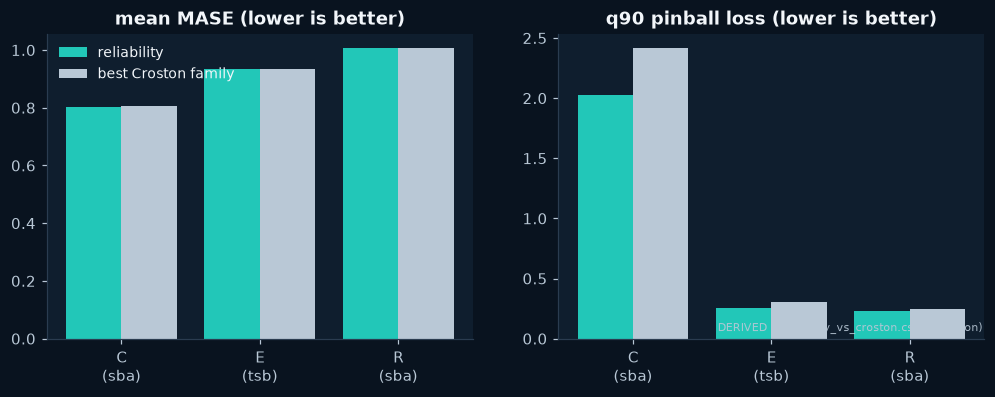

MASE verdicts: {'C': 'reliability better', 'E': 'tie (|diff| < 0.001)', 'R': 'tie (|diff| < 0.001)'}; CIs overlap in 3 of 3 classes
reliability has the lower q90 pinball loss in 3 of 3 classes


In [5]:
rc = pd.read_csv(ROOT / "outputs/forecasting/reliability_vs_croston.csv")
display(rc)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(rc))
for ax, (a, b, title) in zip(axes, [("reliability_mase", "croston_family_mase", "mean MASE (lower is better)"),
                                    ("reliability_pinball_q90", "croston_family_pinball_q90", "q90 pinball loss (lower is better)")]):
    ax.bar(x - 0.2, rc[a], width=0.4, color=TEAL, label="reliability")
    ax.bar(x + 0.2, rc[b], width=0.4, color=TITANIUM, label="best Croston family")
    ax.set_xticks(x); ax.set_xticklabels([f"{c}\n({m})" for c, m in zip(rc.part_class, rc.best_croston_family)]); ax.set_title(title)
axes[0].legend(frameon=False); stamp(axes[1], "reliability_vs_croston.csv (selection)", "DERIVED"); plt.show()
better_q90 = (rc.reliability_pinball_q90 < rc.croston_family_pinball_q90).sum()
print(f"MASE verdicts: {dict(zip(rc.part_class, rc.mase_verdict))}; CIs overlap in {int(rc.cis_overlap.sum())} of {len(rc)} classes")
print(f"reliability has the lower q90 pinball loss in {better_q90} of {len(rc)} classes")

On point accuracy the reliability model ties or narrowly leads the best Croston-family method, with overlapping intervals. On the upper quantile, which is what sizes stock, it leads in every class. It also gives what a time-series method cannot: a rate tied to exposure, so a fleet plan change moves the forecast.

## 5. REAL-data benchmark: Monash Car Parts (unchanged from v1)

To show the methods are implemented correctly and behave as the literature expects, they run on the public **Car Parts** dataset (2,674 monthly series, 12-month horizon). Data provenance **REAL**, metrics **DERIVED**. This benchmark does not depend on the simulated world, so it is the same as in v1. Source: Godahewa, Bergmeir, Webb, Hyndman & Montero-Manso (2021), Monash Time Series Forecasting Archive, Zenodo record 4656021, CC BY 4.0; original data from Hyndman (2015), R package expsmooth.

REAL data / DERIVED metrics · CC BY 4.0 · https://zenodo.org/records/4656021
Car Parts dataset, Monash Time Series Forecasting Archive (Godahewa, Bergmeir, Webb, Hyndman & Montero-Manso, 2021), Zenodo record 4656021, licensed CC BY 4.0; original data from Hyndman (2015), R package expsmooth.


,n_mase_defined,mase,mase_ci_lo,mase_ci_hi,mase_median,bias,cov_q90,pinball_q90
method,,,,,,,,
zero,2658,0.777,0.728,0.826,0.372,-0.391,0.261,4.226
naive,2658,1.226,1.147,1.311,0.528,0.089,0.475,3.182
ma,2658,1.103,1.047,1.158,0.714,0.056,0.749,1.466
croston,2658,1.327,1.271,1.388,0.904,0.124,0.842,1.509
sba,2658,1.258,1.203,1.317,0.839,0.058,0.815,1.575
tsb,2658,1.069,1.021,1.124,0.686,0.040,0.812,1.236
adida,2658,1.061,1.016,1.109,0.708,0.018,0.830,1.284
imapa,2658,1.056,1.011,1.108,0.694,0.030,0.833,1.185
bootstrap,2658,1.274,1.231,1.325,0.913,0.206,0.909,1.469


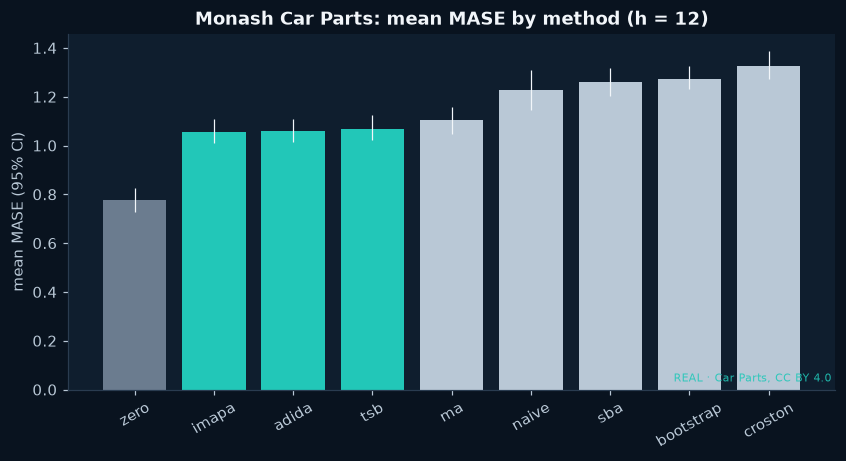

In [6]:
mon = load_json("outputs/forecasting/monash_benchmark.json")
print(mon["data_provenance"], "data /", mon["provenance"], "metrics ·", mon["licence"], "·", mon["source_url"])
print(mon["attribution"])
mr_ = pd.DataFrame(mon["results"]).set_index("method")
display(mr_[["n_mase_defined", "mase", "mase_ci_lo", "mase_ci_hi", "mase_median", "bias", "cov_q90", "pinball_q90"]].round(3))
order = mr_.sort_values("mase").index
fig, ax = plt.subplots()
colors = [SLATE if m == "zero" else (TEAL if m in ("imapa", "adida", "tsb") else TITANIUM) for m in order]
ax.bar(order, mr_.loc[order, "mase"], color=colors,
       yerr=[mr_.loc[order, "mase"] - mr_.loc[order, "mase_ci_lo"], mr_.loc[order, "mase_ci_hi"] - mr_.loc[order, "mase"]],
       error_kw=dict(ecolor=ICE, lw=0.8))
ax.set(ylabel="mean MASE (95% CI)", title="Monash Car Parts: mean MASE by method (h = 12)")
ax.tick_params(axis="x", rotation=30); stamp(ax, "Car Parts, CC BY 4.0", "REAL"); plt.show()

As in the literature, the all-zero forecast wins on MASE: many series fade out during the test year, and MAE-type metrics reward the median, which is often 0. That is why `zero` is a benchmark only and never a champion. Among eligible methods, the aggregation methods and TSB lead, and the classical Croston is weakest, which matches published results on this dataset.

## 6. Truth recovery: do history-based estimates beat the vendor quotes?

After the holdout, the evaluation compared the history-based estimates with the hidden truth (`outputs/holdout/truth_recovery.json`, DERIVED; the notebook reads only this summary, never the truth tables). The metric is the median absolute log error |ln(estimate / truth)|; 0.07 is about 7% off.

,param,n,vendor_quote,history_estimate,share_estimate_closer
0,MTBUR (all),75,0.139,0.071,0.640
1,MTBUR (E),35,0.128,0.072,0.629
2,MTBUR (R),40,0.165,0.069,0.650
3,purchase lead time,120,0.061,0.062,NaN


MTBUR, all 75 R/E parts: history estimate about 7% off the truth vs about 14% for the vendor quote; the estimate is closer for 64% of parts


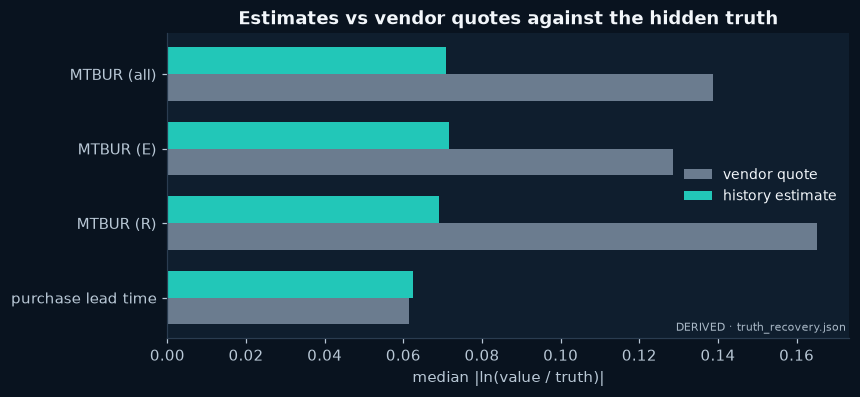

lead-time parts whose supplier changed:


,pn,true,est,quoted,changed
0,GN-33-E033,73.245404,69.875,24.8,True


In [7]:
tr = load_json("outputs/holdout/truth_recovery.json")
rows = [dict(param=f"MTBUR ({k})", n=v["n_parts"], vendor_quote=v["quoted_mdale"], history_estimate=v["estimated_mdale"],
             share_estimate_closer=v["share_estimate_closer"]) for k, v in tr["reliability"].items()]
lt = tr["lead_time"]
rows.append(dict(param="purchase lead time", n=lt["n_parts"], vendor_quote=lt["quoted_mdale"], history_estimate=lt["estimated_mdale"],
                 share_estimate_closer=np.nan))
trd = pd.DataFrame(rows); display(trd.round(3))
a = tr["reliability"]["all"]
print(f"MTBUR, all {a['n_parts']} R/E parts: history estimate about {a['estimated_mdale']:.0%} off the truth vs about "
      f"{a['quoted_mdale']:.0%} for the vendor quote; the estimate is closer for {a['share_estimate_closer']:.0%} of parts")
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(trd))
ax.barh(y + 0.18, trd.vendor_quote, height=0.36, color=SLATE, label="vendor quote")
ax.barh(y - 0.18, trd.history_estimate, height=0.36, color=TEAL, label="history estimate")
ax.set_yticks(y); ax.set_yticklabels(trd.param); ax.invert_yaxis()
ax.set(xlabel="median |ln(value / truth)|", title="Estimates vs vendor quotes against the hidden truth")
ax.legend(frameon=False); stamp(ax, "truth_recovery.json", "DERIVED"); plt.show()
print("lead-time parts whose supplier changed:"); display(pd.DataFrame(lt["changed_parts"]))

The history-based reliability estimate roughly halves the MTBUR error of the vendor quote. After calibration the quotes are only mildly optimistic, so the edge is real but not dramatic, which is the honest size of it. Lead times were mostly quoted correctly, so the estimate only ties the quote overall. On the one part whose supplier changed (PS4) it is decisive: the recency-weighted estimate is close to the new lead time while the master data still quotes the old one.

## Summary

* Point accuracy is close to a tie between methods, and the selection ranking only partly survives on the holdout.
* The frozen champions were the best on the holdout in only a minority of cells (printed above); this is reported, not re-tuned.
* The reliability model ties the Croston family on MASE and leads on the upper quantile in every class.
* The implementation behaves as published on the REAL Monash Car Parts benchmark.
* History-based MTBUR is about half as far from the truth as the vendor quote.

Next: `03_policy_and_frontier.ipynb` turns these forecasts into stocking policies and tests them on the holdout.